In [130]:
import torch
from torch import nn 
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from  sklearn.model_selection import train_test_split


In [131]:
from pathlib import Path

zip_path = Path(
    r"C:\Users\User\Downloads\Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui.zip"
    )

data_root = Path(r"D:\python projects\projects\Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui\Epic and CSCR hospital Dataset")

In [132]:
train_dir = data_root / "Train"
test_dir = data_root / "Test"

image_transform = transforms.Compose([
    transforms.Resize([128,128]),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

train_full = datasets.ImageFolder(train_dir, transform=image_transform)
test_data = datasets.ImageFolder(test_dir, transform=image_transform)

assert train_full.class_to_idx == test_data.class_to_idx, (
    "training and testing folders do not match"
)

print("Classes:", train_full.class_to_idx)
print("Training images:", len(train_full))
print("Test images:", len(test_data))

Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training images: 9650
Test images: 2414


In [133]:
indices = list(range(len(train_full)))
labels = train_full.targets

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels,
)

train_data = Subset(train_full, train_indices)
val_data = Subset(train_full, val_indices)
num_classes = len(train_full)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(len(train_data), len(val_data), len(test_data))

7720 1930 2414


In [134]:
import torch
print("CUDA Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")


CUDA Available: True
GPU Name: NVIDIA GeForce RTX 3060 Laptop GPU


In [135]:
import torch
from torch import nn

model = build_model(num_classes, device)

def build_model(num_classes, device):
    return nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),

        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Linear(128, num_classes),
    ).to(device)

num_classes = len(class_names)

torch.manual_seed(41)
model = build_model(num_classes, device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

# Shape check before training
sample_images, _ = next(iter(train_loader))
with torch.no_grad():
    print("Output shape:", model(sample_images.to(device)).shape)

Total parameters: 93,636
Output shape: torch.Size([32, 4])


In [136]:
import numpy as np
train_labels = np.asarray(train_full.targets)[train_indices]
train_counts = np.bincount(train_labels, minlength=num_classes)

if np.any(train_counts == 0):
    raise ValueError("At least one class has no training images.")

weights = train_counts.sum() / (num_classes * train_counts)

print("Class order:", train_full.class_to_idx)
for name, count, weight in zip(
    train_full.classes, train_counts, weights
):
    print(f"{name:<15} count={count:<5} weight={weight:.3f}")

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device,
)

Class order: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
glioma          count=2414  weight=0.800
meningioma      count=1747  weight=1.105
notumor         count=1556  weight=1.240
pituitary       count=2003  weight=0.964


Epoch 42/75: train loss=0.259, train acc=0.905, val loss=0.291, val acc=0.903


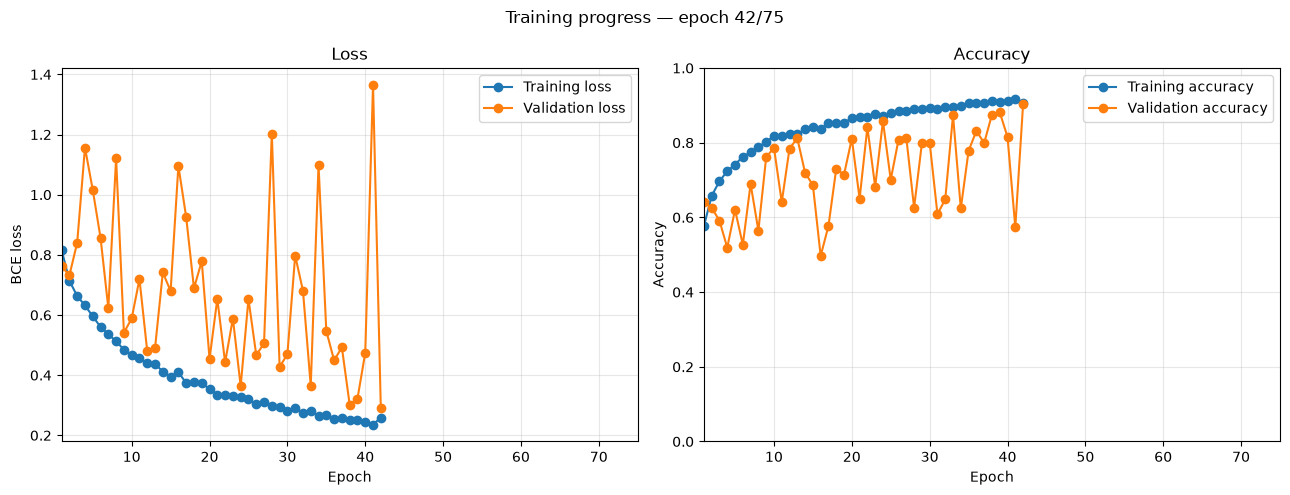

KeyboardInterrupt: 

In [137]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

learning_rate = 0.1
epochs = 75

# ----- CLASS AND TRAINING-COUNT SETUP -----
num_classes = len(train_full.classes)
classes = train_full.classes

# Get labels from the training subset only
all_labels = np.asarray(train_full.targets)
train_labels = all_labels[train_indices]

# Count samples in each class
train_counts = np.bincount(
    train_labels,
    minlength=num_classes
).astype(np.float32)

if np.any(train_counts == 0):
    raise ValueError(
        f"At least one class has zero training examples: "
        f"{train_counts}"
    )

# Balanced one-vs-rest weights
pw = (
    train_counts.sum() - train_counts
) / train_counts

RECALL_BOOST = 1.0

pos_weight = torch.tensor(
    pw * RECALL_BOOST,
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum = 0.9,
    weight_decay = 1e-4
)

print("Classes:", classes)
print("Training counts:", train_counts.astype(int))
print("pos_weight:", pos_weight)

# ----- TRAINING HISTORY -----
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

# ----- TRAINING LOOP -----
for epoch in range(epochs):
    # ---------- TRAIN ----------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).long()

        optimizer.zero_grad()

        logits = model(images)

        # BCEWithLogitsLoss requires targets shaped like logits:
        # logits:  [batch_size, num_classes]
        # targets: [batch_size, num_classes]
        targets = F.one_hot(
            labels,
            num_classes=num_classes
        ).float()

        assert logits.shape == targets.shape, (
            f"Shape mismatch: logits={logits.shape}, "
            f"targets={targets.shape}"
        )

        loss = criterion(logits, targets)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            (logits.argmax(dim=1) == labels).sum().item()
        )
        train_total += batch_size

    # ---------- VALIDATE ----------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            logits = model(images)

            targets = F.one_hot(
                labels,
                num_classes=num_classes
            ).float()

            assert logits.shape == targets.shape, (
                f"Shape mismatch: logits={logits.shape}, "
                f"targets={targets.shape}"
            )

            loss = criterion(logits, targets)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                (logits.argmax(dim=1) == labels).sum().item()
            )
            val_total += batch_size

    # ---------- EPOCH RESULTS ----------
    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # ---------- LIVE PLOTS ----------
    epoch_numbers = range(
        1,
        len(history["train_loss"]) + 1
    )

    fig, (loss_ax, accuracy_ax) = plt.subplots(
        1,
        2,
        figsize=(13, 5)
    )

    # Loss plot
    loss_ax.plot(
        epoch_numbers,
        history["train_loss"],
        marker="o",
        label="Training loss"
    )
    loss_ax.plot(
        epoch_numbers,
        history["val_loss"],
        marker="o",
        label="Validation loss"
    )
    loss_ax.set_title("Loss")
    loss_ax.set_xlabel("Epoch")
    loss_ax.set_ylabel("BCE loss")
    loss_ax.set_xlim(1, max(2, epochs))
    loss_ax.grid(alpha=0.3)
    loss_ax.legend()

    # Accuracy plot
    accuracy_ax.plot(
        epoch_numbers,
        history["train_accuracy"],
        marker="o",
        label="Training accuracy"
    )
    accuracy_ax.plot(
        epoch_numbers,
        history["val_accuracy"],
        marker="o",
        label="Validation accuracy"
    )
    accuracy_ax.set_title("Accuracy")
    accuracy_ax.set_xlabel("Epoch")
    accuracy_ax.set_ylabel("Accuracy")
    accuracy_ax.set_xlim(1, max(2, epochs))
    accuracy_ax.set_ylim(0, 1)
    accuracy_ax.grid(alpha=0.3)
    accuracy_ax.legend()

    fig.suptitle(
        f"Training progress — epoch {epoch + 1}/{epochs}"
    )
    fig.tight_layout()

    clear_output(wait=True)

    print(
        f"Epoch {epoch + 1}/{epochs}: "
        f"train loss={train_loss:.3f}, "
        f"train acc={train_accuracy:.3f}, "
        f"val loss={val_loss:.3f}, "
        f"val acc={val_accuracy:.3f}"
    )

    display(fig)
    plt.close(fig)

print(
    "Completed epochs:",
    len(history["train_loss"])
)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities > 0.5).float().argmax(dim=1).cpu()

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.tolist())

print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=list(range(len(train_full.classes))),
        target_names=train_full.classes,
        zero_division=0,
    )
)

print(
    confusion_matrix(
        true_labels,
        predicted_labels,
        labels=list(range(len(train_full.classes))),
    )
)



              precision    recall  f1-score   support

      glioma       0.99      0.53      0.69       755
  meningioma       0.38      0.99      0.55       546
     notumor       0.95      0.82      0.88       487
   pituitary       0.97      0.28      0.43       626

    accuracy                           0.62      2414
   macro avg       0.82      0.65      0.64      2414
weighted avg       0.84      0.62      0.63      2414

[[397 342  14   2]
 [  1 538   4   3]
 [  0  89 398   0]
 [  2 448   1 175]]


              precision    recall  f1-score   support

      glioma       1.00      0.65      0.79       604
  meningioma       0.56      0.99      0.72       436
     notumor       0.97      0.98      0.97       389
   pituitary       0.99      0.74      0.85       501

    accuracy                           0.82      1930
   macro avg       0.88      0.84      0.83      1930
weighted avg       0.89      0.82      0.82      1930



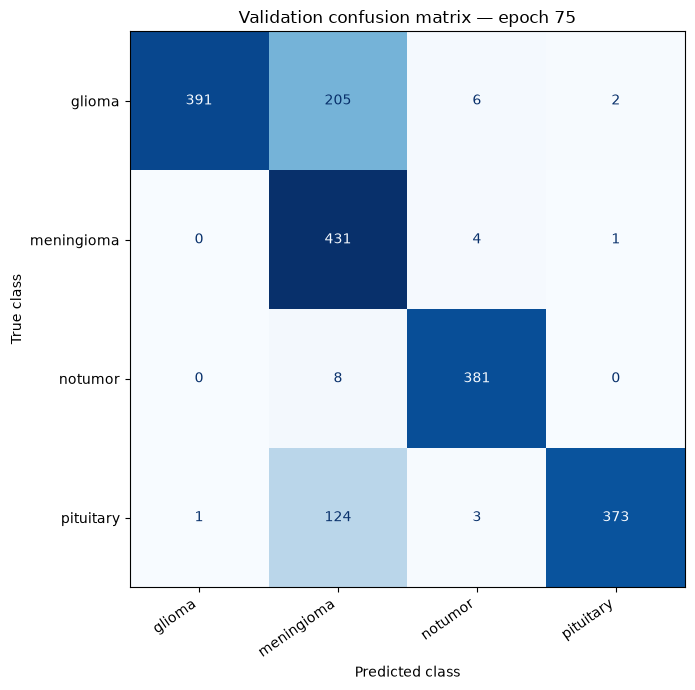

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

class_names = train_full.classes
class_ids = list(range(len(class_names)))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title(f"Validation confusion matrix — epoch {len(history['train_loss'])}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.tight_layout()
plt.show()

Test images:        2414
Test accuracy:      74.52%
Balanced accuracy:  78.32%

              precision    recall  f1-score   support

      glioma      0.997     0.417     0.588       755
  meningioma      0.480     0.984     0.645       546
     notumor      0.949     0.988     0.968       487
   pituitary      0.987     0.744     0.849       626

    accuracy                          0.745      2414
   macro avg      0.853     0.783     0.762      2414
weighted avg      0.868     0.745     0.745      2414



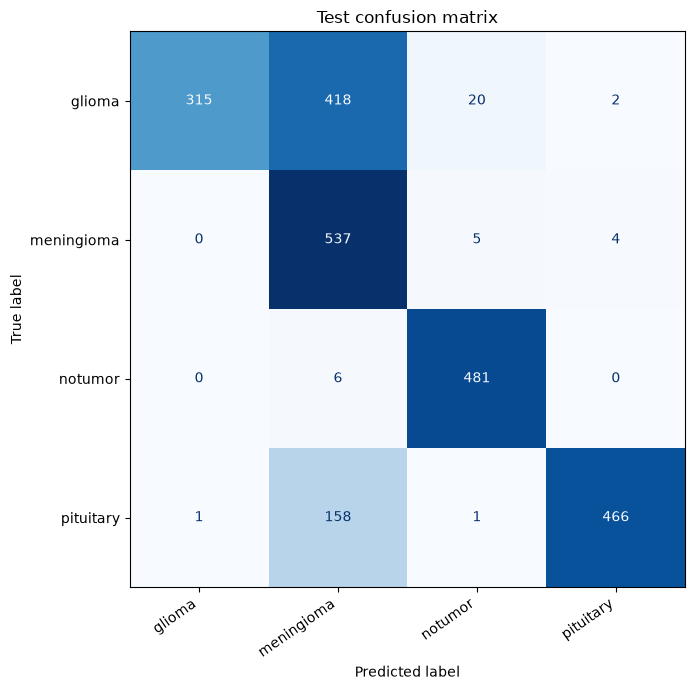

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

class_ids = list(range(num_classes))

test_accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)

print(f"Test images:        {len(y_true)}")
print(f"Test accuracy:      {test_accuracy:.2%}")
print(f"Balanced accuracy:  {balanced_acc:.2%}")
print()
print(
    classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        digits=3,
        zero_division=0,
    )
)

cm = confusion_matrix(y_true, y_pred, labels=class_ids)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Test confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.tight_layout()
plt.show()